In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import os

# Configuração do layout gráfico
sb.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

In [2]:
caminho_dados = r"../data/processed/dados_sensores_tratados.csv"
if not os.path.exists(caminho_dados):
    caminho_dados = r"data/processed/dados_sensores_tratados.csv"
if not os.path.exists(caminho_dados):
    caminho_dados = r"C:\Users\mateus_s_cavalheiro\Documents\GitHub\VulcanTech-Smart-Metals-S.A\data\processed\dados_sensores_tratados.csv"

df_limpo = pd.read_csv(caminho_dados)
df_limpo['timestamp'] = pd.to_datetime(df_limpo['timestamp'])

print(f"Dataset carregado com sucesso: {df_limpo.shape[0]} registros e {df_limpo.shape[1]} colunas.")
df_limpo.head()

Dataset carregado com sucesso: 10000 registros e 35 colunas.


,timestamp,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,...,iem_rolling_std_30min,iem_rolling_mean_2h,iem_rolling_std_2h,temperatura_fuso_c_norm_liga,vibracao_triaxial_rms_mms_norm_liga,torque_fuso_nm_norm_liga,vazao_refrigerante_lmin_norm_liga,corrente_estator_amp_norm_liga,pressao_hidraulica_bar_norm_liga,nivel_ruido_db_norm_liga
0,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,58.18,1.90,101.89,29.31,27.77,162.28,52.93,...,0.000000,6.387034,0.000000,1.066029,0.877499,0.872541,1.084999,0.925210,1.029166,0.913939
1,2026-10-01 00:35:00,CEL-201,Aco_Carbono_316L,45.76,1.94,102.71,32.53,27.18,169.21,53.80,...,0.314220,6.164847,0.314220,0.838458,0.895973,0.879563,1.204198,0.905553,1.073116,0.928961
2,2026-10-01 00:40:00,CEL-201,Aco_Carbono_316L,53.65,1.42,95.06,25.67,31.14,152.83,53.54,...,0.674757,5.797002,0.674757,0.983026,0.655815,0.814052,0.950254,1.037488,0.969235,0.924472
3,2026-10-01 01:00:00,CEL-201,Aluminio_7075,70.92,2.54,103.13,27.39,31.02,166.93,45.08,...,1.801247,6.654464,1.801247,1.624843,1.491518,1.108559,0.996657,1.305040,1.054574,0.980388
4,2026-10-01 01:05:00,CEL-201,Aluminio_7075,61.19,1.40,113.46,29.11,20.19,162.58,48.46,...,1.677409,6.378662,1.677409,1.401920,0.822096,1.219597,1.059244,0.849412,1.027093,1.053895


In [3]:
print("Valores ausentes (NaN) por sensor/feature:")
print(df_limpo.isna().sum())

print("\n--- Resumo Estatístico das Variáveis Críticas ---")
display(df_limpo[[
    'temperatura_fuso_c', 'vibracao_triaxial_rms_mms', 'torque_fuso_nm',
    'vazao_refrigerante_lmin', 'corrente_estator_amp', 'pressao_hidraulica_bar',
    'nivel_ruido_db', 'iem'
]].describe().round(2))

Valores ausentes (NaN) por sensor/feature:
timestamp                                       0
id_celula                                       0
liga_metalica                                   0
temperatura_fuso_c                              0
vibracao_triaxial_rms_mms                       0
torque_fuso_nm                                  0
vazao_refrigerante_lmin                         0
corrente_estator_amp                            0
pressao_hidraulica_bar                          0
nivel_ruido_db                                  0
tipo_falha                                      0
iem                                             0
temperatura_fuso_c_rolling_mean_30min           0
temperatura_fuso_c_rolling_std_30min            0
temperatura_fuso_c_rolling_mean_2h              0
temperatura_fuso_c_rolling_std_2h               0
vibracao_triaxial_rms_mms_rolling_mean_30min    0
vibracao_triaxial_rms_mms_rolling_std_30min     0
vibracao_triaxial_rms_mms_rolling_mean_2h       0
vibraca

,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,iem
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,54.36,2.12,116.10,27.14,29.79,157.95,57.55,10.49
std,12.75,1.07,28.66,4.12,7.73,11.32,12.78,11.09
min,27.71,0.36,48.84,5.00,10.73,100.39,32.28,1.15
25%,45.37,1.55,96.25,26.24,24.45,153.26,47.99,5.22
50%,52.17,1.86,110.99,27.72,28.48,159.13,55.24,7.05
75%,61.39,2.26,131.84,29.16,34.11,164.79,66.33,10.57
max,120.41,8.13,255.92,35.68,66.24,190.62,114.99,117.62


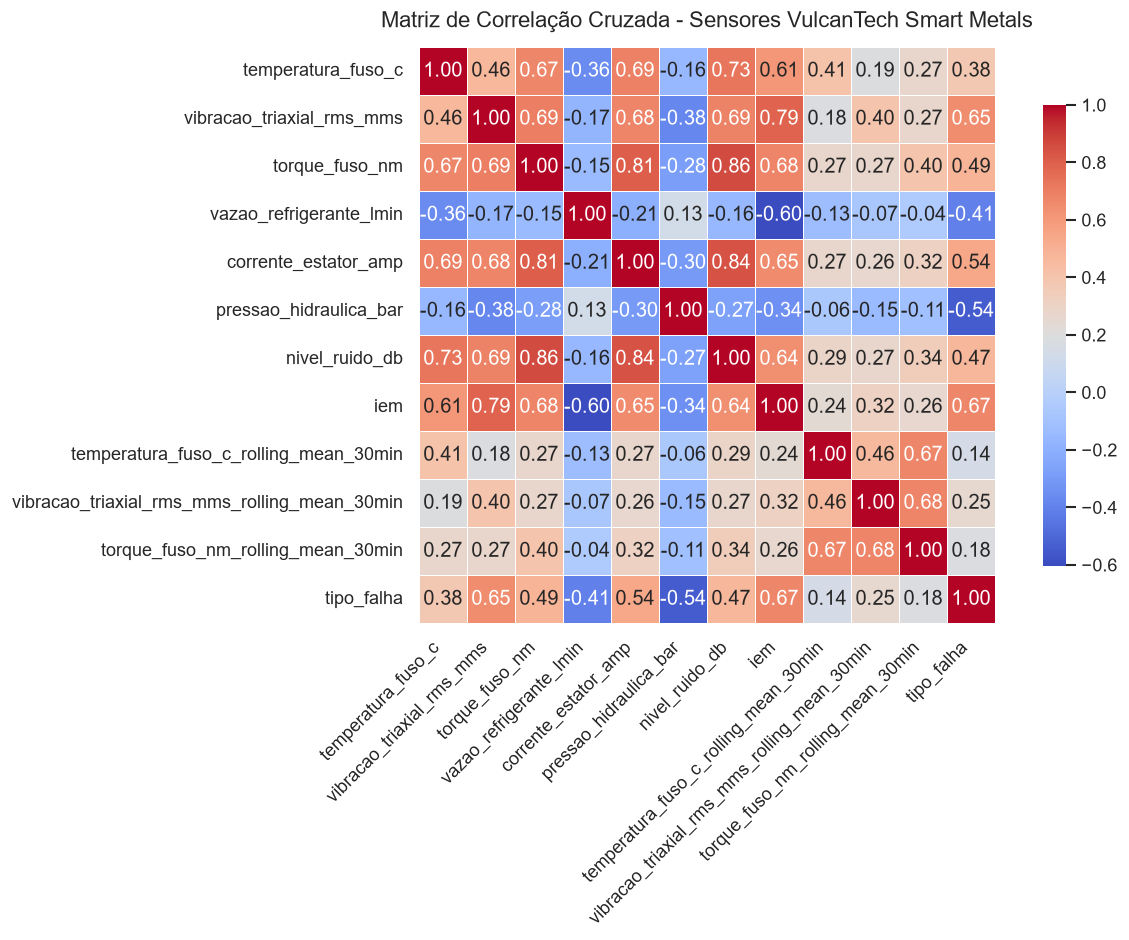

In [4]:
colunas_eda = [
    'temperatura_fuso_c', 'vibracao_triaxial_rms_mms', 'torque_fuso_nm',
    'vazao_refrigerante_lmin', 'corrente_estator_amp', 'pressao_hidraulica_bar',
    'nivel_ruido_db', 'iem', 'temperatura_fuso_c_rolling_mean_30min',
    'vibracao_triaxial_rms_mms_rolling_mean_30min', 'torque_fuso_nm_rolling_mean_30min', 'tipo_falha'
]

matriz_corr = df_limpo[colunas_eda].corr()

plt.figure(figsize=(11, 8))
sb.heatmap(
    matriz_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title('Matriz de Correlação Cruzada - Sensores VulcanTech Smart Metals', fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\1096298918.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='liga_metalica', y='torque_fuso_nm', ax=axes[0], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\1096298918.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='liga_metalica', y='corrente_estator_amp', ax=axes[1], palette='Set2')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\1096298918.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplo

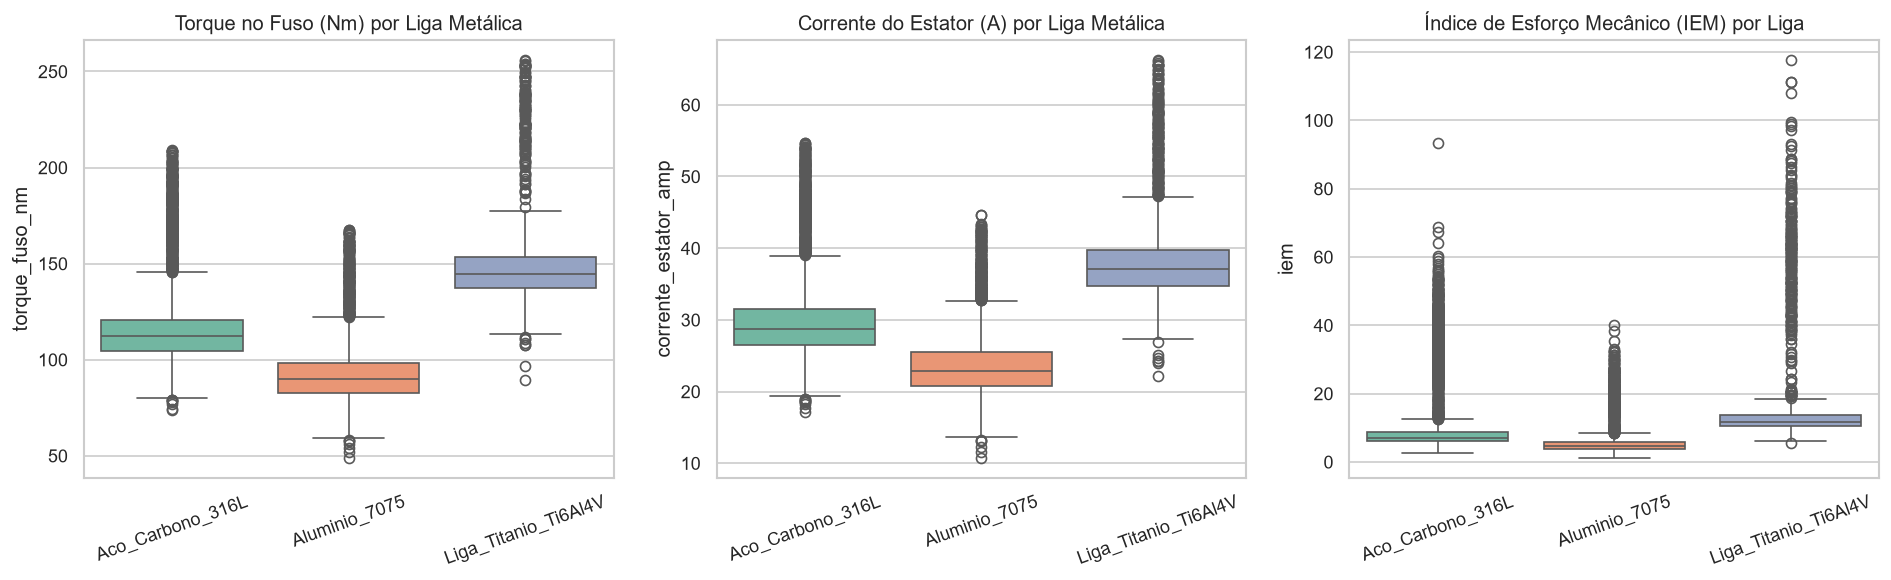

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sb.boxplot(data=df_limpo, x='liga_metalica', y='torque_fuso_nm', ax=axes[0], palette='Set2')
axes[0].set_title('Torque no Fuso (Nm) por Liga Metálica')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20)

sb.boxplot(data=df_limpo, x='liga_metalica', y='corrente_estator_amp', ax=axes[1], palette='Set2')
axes[1].set_title('Corrente do Estator (A) por Liga Metálica')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20)

sb.boxplot(data=df_limpo, x='liga_metalica', y='iem', ax=axes[2], palette='Set2')
axes[2].set_title('Índice de Esforço Mecânico (IEM) por Liga')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\2538893854.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='descricao_falha', y='temperatura_fuso_c', ax=axes[0], palette='tab10')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\2538893854.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=df_limpo, x='descricao_falha', y='vibracao_triaxial_rms_mms', ax=axes[1], palette='tab10')
C:\Users\mateus_s_cavalheiro\AppData\Local\Temp\ipykernel_15124\2538893854.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same eff

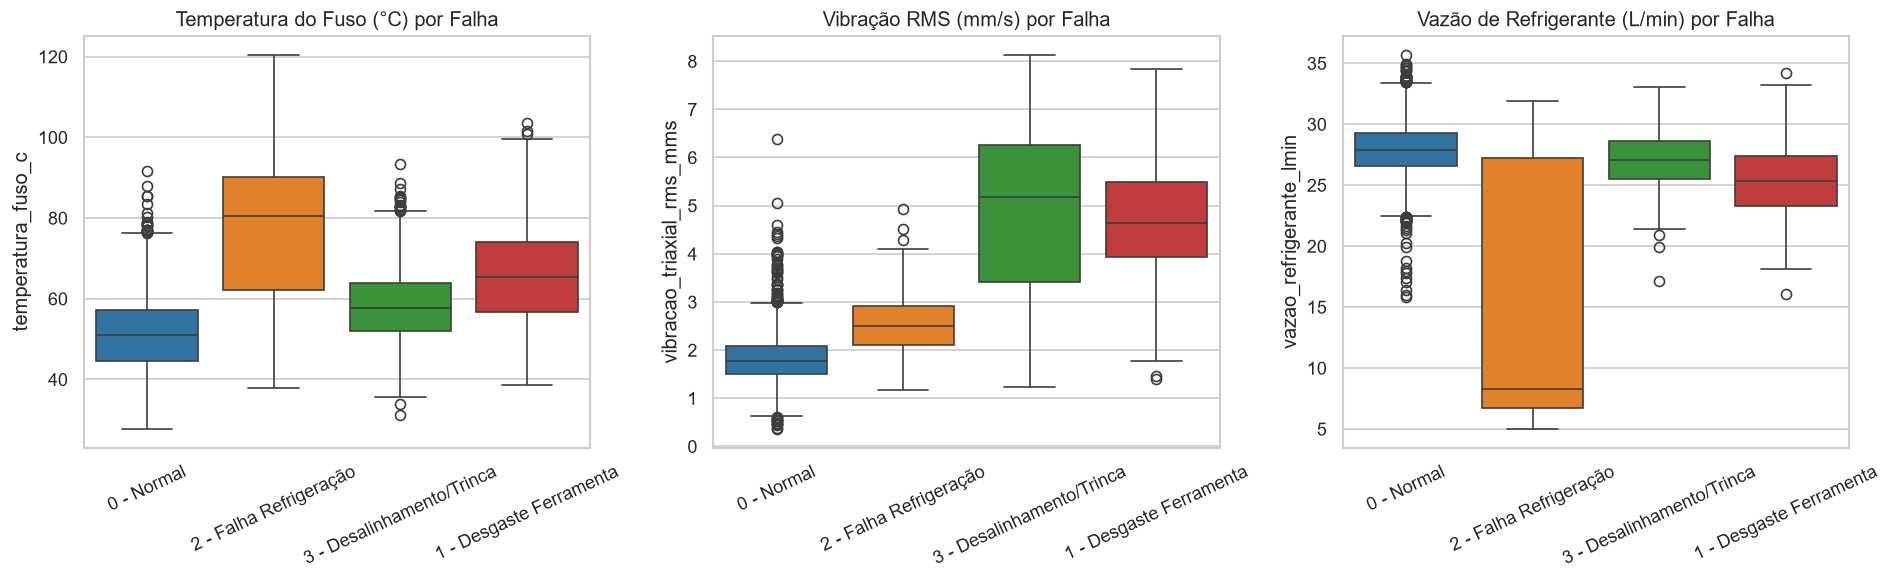

In [6]:
rotulos_falha = {
    0: '0 - Normal',
    1: '1 - Desgaste Ferramenta',
    2: '2 - Falha Refrigeração',
    3: '3 - Desalinhamento/Trinca'
}
df_limpo['descricao_falha'] = df_limpo['tipo_falha'].map(rotulos_falha)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sb.boxplot(data=df_limpo, x='descricao_falha', y='temperatura_fuso_c', ax=axes[0], palette='tab10')
axes[0].set_title('Temperatura do Fuso (°C) por Falha')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)

sb.boxplot(data=df_limpo, x='descricao_falha', y='vibracao_triaxial_rms_mms', ax=axes[1], palette='tab10')
axes[1].set_title('Vibração RMS (mm/s) por Falha')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=25)

sb.boxplot(data=df_limpo, x='descricao_falha', y='vazao_refrigerante_lmin', ax=axes[2], palette='tab10')
axes[2].set_title('Vazão de Refrigerante (L/min) por Falha')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()